# Two-Asset Portfolios: Why Correlation Matters

In this notebook, we will study how two assets can be combined into a portfolio and, especially, how **correlation changes portfolio risk**.

The central question is:

> **What happens to portfolio risk when correlation changes, while the individual assets remain the same?**

### Learning objectives

By the end of the notebook, you should be able to:

1. Calculate the expected return of a two-asset portfolio.
2. Calculate portfolio volatility.
3. Explain why correlation affects risk but not expected return.
4. Understand the diversification effect of lower correlation.
5. Identify the minimum-volatility portfolio.
6. Apply the same ideas to financial return data.

## 1. Start with the intuition

Suppose we combine two assets:

- **Asset 1** has a high expected return and high volatility.
- **Asset 2** has a lower expected return and lower volatility.

The portfolio return is simply a weighted average:

$$
E(R_P)=w_1E(R_1)+w_2E(R_2)
$$

with:

$$
w_1+w_2=1
$$

Portfolio risk is different. It depends not only on the risk of each asset, but also on **how the two assets move together**:

$$
\sigma_P=
\sqrt{
w_1^2\sigma_1^2+
w_2^2\sigma_2^2+
2w_1w_2\sigma_1\sigma_2\rho_{12}
}
$$

The new element is $\rho_{12}$, the correlation between the returns of the two assets.

### Key idea

> **Expected return depends on weights and expected returns. Portfolio risk also depends on correlation.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import requests
from io import StringIO
from tqdm import tqdm

plt.style.use("ggplot")

## 2. Define our two assets

We will keep the characteristics of the two assets fixed throughout the first part of the notebook.

Only the correlation will change.

In [2]:
# Asset characteristics
ret1 = 0.20
ret2 = 0.10

std1 = 0.25
std2 = 0.15

# Initial portfolio weights
w1 = 0.40
w2 = 0.60

### Exercise 1 — Portfolio return

Before using Python, calculate the expected return of the portfolio by hand.

Use:

- $w_1=0.40$
- $w_2=0.60$
- $E(R_1)=20\%$
- $E(R_2)=10\%$

**Question:** What is the portfolio expected return?

In [3]:
# Your code here

## 3. Create reusable portfolio functions

We will use the same two functions throughout the notebook.

In [4]:
def calc_portfolio_return(w1, w2, r1, r2):
    """Calculate the expected return of a two-asset portfolio."""
    return w1 * r1 + w2 * r2


def calc_portfolio_std(w1, w2, std1, std2, rho):
    """Calculate the volatility of a two-asset portfolio."""
    return np.sqrt(
        w1**2 * std1**2
        + w2**2 * std2**2
        + 2 * w1 * w2 * std1 * std2 * rho
    )

## 4. Case 1: Perfect positive correlation

Let:

$$
\rho_{12}=1
$$

The two assets move perfectly together.

In this extreme case:

> **There is no diversification benefit.**

The portfolio volatility becomes:

$$
\sigma_P=w_1\sigma_1+w_2\sigma_2
$$

In [5]:
rho = 1

portfolio_return = calc_portfolio_return(w1, w2, ret1, ret2)
portfolio_std = calc_portfolio_std(w1, w2, std1, std2, rho)

print(f"Portfolio return: {portfolio_return:.2%}")
print(f"Portfolio volatility: {portfolio_std:.2%}")

Portfolio return: 14.00%
Portfolio volatility: 19.00%


### Exercise 2 — Predict before plotting

If $\rho=1$:

1. What do you expect the set of possible portfolios to look like in the return-volatility plane?
2. Can any portfolio have lower volatility than both individual assets?
3. Does changing the weights change expected return?

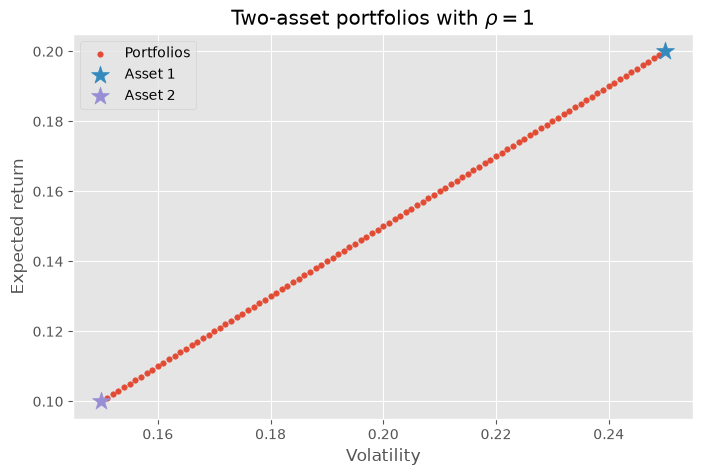

In [6]:
# Generate portfolios with different weights
weights_1 = np.linspace(0, 1, 101)

returns_rho1 = []
vols_rho1 = []

for w1_i in weights_1:
    w2_i = 1 - w1_i

    returns_rho1.append(
        calc_portfolio_return(w1_i, w2_i, ret1, ret2)
    )
    vols_rho1.append(
        calc_portfolio_std(w1_i, w2_i, std1, std2, rho)
    )

plt.figure(figsize=(8, 5))
plt.scatter(vols_rho1, returns_rho1, s=15, label="Portfolios")
plt.scatter(std1, ret1, marker="*", s=180, label="Asset 1")
plt.scatter(std2, ret2, marker="*", s=180, label="Asset 2")

plt.xlabel("Volatility")
plt.ylabel("Expected return")
plt.title(r"Two-asset portfolios with $\rho=1$")
plt.legend()
plt.show()

### Interpretation

With perfect positive correlation, all portfolios lie on a straight line between the two assets.

There is no additional risk reduction from combining the assets.

The only thing we are doing is moving from one asset to the other by changing the weights.

## 5. What if correlation is lower?

Now we keep **everything else unchanged** and modify only the correlation.

This is the central experiment of the notebook.

### Exercise 3 — Compare three correlations

Calculate the volatility of the same 40%-60% portfolio for:

- $\rho=1$
- $\rho=0$
- $\rho=-0.5$

Before running the code, predict:

> Which portfolio should have the lowest volatility?

In [7]:
# Your code here

### Main lesson

Notice something important:

- The assets are the same.
- Their expected returns are the same.
- Their individual volatilities are the same.
- The portfolio weights are the same.

Only **correlation** changed.

Yet portfolio volatility changed.

That is the diversification effect.

## 6. Case 2: Perfect negative correlation

Now let:

$$
\rho_{12}=-1
$$

The two assets move perfectly in opposite directions.

This is the strongest possible diversification case.

Portfolio volatility becomes:

$$
\sigma_P=
|w_1\sigma_1-w_2\sigma_2|
$$

For one particular combination of weights, portfolio volatility can even become zero.

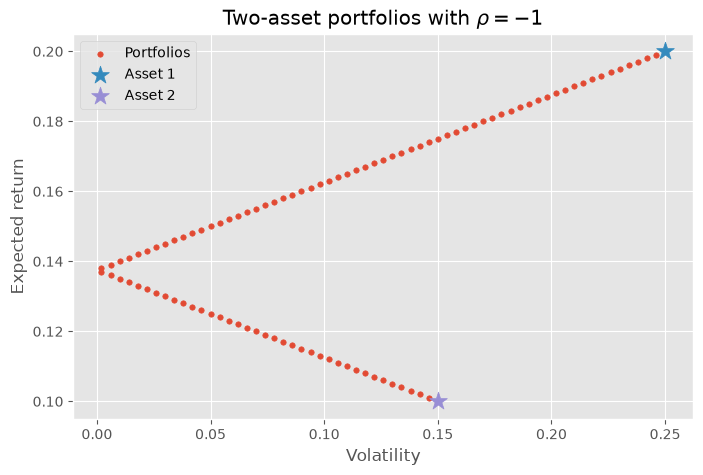

In [8]:
rho = -1

returns_rho_minus1 = []
vols_rho_minus1 = []

for w1_i in weights_1:
    w2_i = 1 - w1_i

    returns_rho_minus1.append(
        calc_portfolio_return(w1_i, w2_i, ret1, ret2)
    )
    vols_rho_minus1.append(
        calc_portfolio_std(w1_i, w2_i, std1, std2, rho)
    )

plt.figure(figsize=(8, 5))
plt.scatter(vols_rho_minus1, returns_rho_minus1, s=15, label="Portfolios")
plt.scatter(std1, ret1, marker="*", s=180, label="Asset 1")
plt.scatter(std2, ret2, marker="*", s=180, label="Asset 2")

plt.xlabel("Volatility")
plt.ylabel("Expected return")
plt.title(r"Two-asset portfolios with $\rho=-1$")
plt.legend()
plt.show()

### Exercise 4 — Find the zero-volatility portfolio

For $\rho=-1$, the minimum-volatility weight of asset 1 is:

$$
w_1=\frac{\sigma_2}{\sigma_1+\sigma_2}
$$

1. Calculate $w_1$.
2. Calculate $w_2$.
3. Calculate the portfolio expected return.
4. Verify that portfolio volatility is zero.

In [9]:
# Your code here

## 7. Compare several correlations

Now we can see the full picture.

We will calculate the portfolio opportunity set for several correlation values:

$$
\rho \in \{-1,-0.8,-0.5,0,0.5,1\}
$$

Before running the next cell, answer:

> **What do you expect to happen to portfolio risk as correlation decreases?**

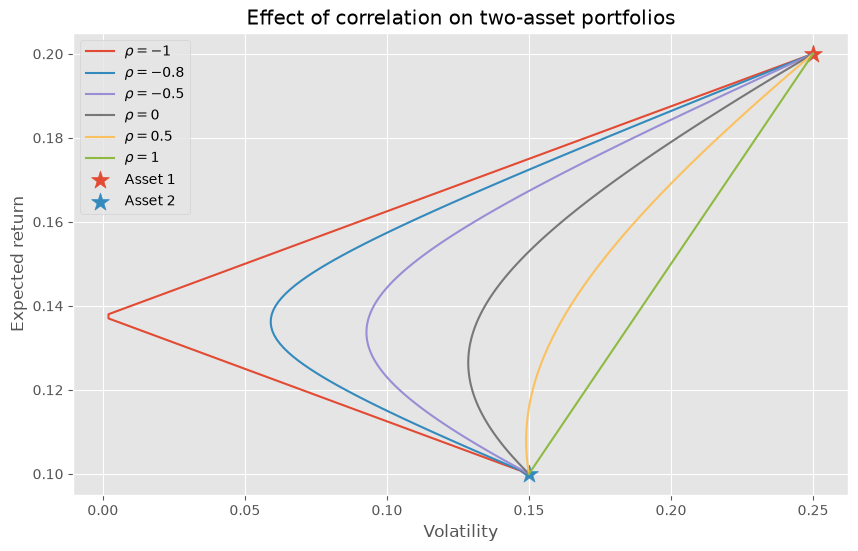

In [10]:
correlation_values = [-1, -0.8, -0.5, 0, 0.5, 1]

plt.figure(figsize=(10, 6))

for rho_i in correlation_values:
    portfolio_returns = []
    portfolio_vols = []

    for w1_i in weights_1:
        w2_i = 1 - w1_i

        portfolio_returns.append(
            calc_portfolio_return(w1_i, w2_i, ret1, ret2)
        )
        portfolio_vols.append(
            calc_portfolio_std(w1_i, w2_i, std1, std2, rho_i)
        )

    plt.plot(
        portfolio_vols,
        portfolio_returns,
        label=fr"$\rho={rho_i}$"
    )

plt.scatter(std1, ret1, marker="*", s=180, label="Asset 1")
plt.scatter(std2, ret2, marker="*", s=180, label="Asset 2")

plt.xlabel("Volatility")
plt.ylabel("Expected return")
plt.title("Effect of correlation on two-asset portfolios")
plt.legend()
plt.show()

### Exercise 5 — Interpret the figure

Answer in words:

1. Which correlation produces the greatest diversification benefit?
2. Which correlation produces no diversification benefit?
3. Does changing correlation change the expected return of a portfolio with fixed weights?
4. Why does the set of portfolios move to the left when correlation decreases?

**Key concept:** moving to the left means achieving the same expected return with less volatility.

## 8. The minimum-volatility portfolio

For any correlation between the two assets, the weight of asset 1 in the minimum-variance portfolio is:

$$
w_1^*=
\frac{
\sigma_2^2-\rho_{12}\sigma_1\sigma_2
}{
\sigma_1^2+\sigma_2^2-2\rho_{12}\sigma_1\sigma_2
}
$$

and:

$$
w_2^*=1-w_1^*
$$

This formula identifies the leftmost point of each portfolio curve.

In [11]:
def min_variance_weights(std1, std2, rho):
    w1 = (std2**2 - rho * std1 * std2) / (
        std1**2 + std2**2 - 2 * rho * std1 * std2
    )
    w2 = 1 - w1
    return w1, w2

### Exercise 6 — Minimum volatility and correlation

Calculate the minimum-volatility portfolio for:

- $\rho=0.8$
- $\rho=0$
- $\rho=-0.5$
- $\rho=-1$

For each case, report:

- $w_1$
- $w_2$
- expected return
- volatility

Then answer:

> How does lower correlation affect the minimum achievable portfolio volatility?

In [12]:
# Your code here

## 9. From theory to data

So far, correlation was an input chosen by us.

Now we will estimate correlation from return data.

The original course material includes datasets designed to illustrate different dependence patterns. We will use one of them to connect the theoretical formulas with observed returns.

In [13]:
# Positive-correlation example
url_pos = (
    "https://raw.githubusercontent.com/alfonso-santos/"
    "microcredencial-carteras-python/refs/heads/Feb-2025/"
    "Tema_1_Activos_Intro/data/precios_corr_pos.csv"
)

prices_pos = pd.read_csv(url_pos, index_col=0, parse_dates=True)
prices_pos.columns = ["Asset 1", "Asset 2"]

returns_pos = np.log(prices_pos).diff().dropna()

print("Estimated correlation:")
print(returns_pos.corr())

prices_pos.head()

Estimated correlation:
         Asset 1  Asset 2
Asset 1  1.00000  0.98014
Asset 2  0.98014  1.00000


,Asset 1,Asset 2
2010-01-04,117.000000,158.000000
2010-01-05,113.192375,156.263037
2010-01-06,111.121152,155.307702
2010-01-07,107.084666,153.467719
2010-01-08,105.076790,152.540900


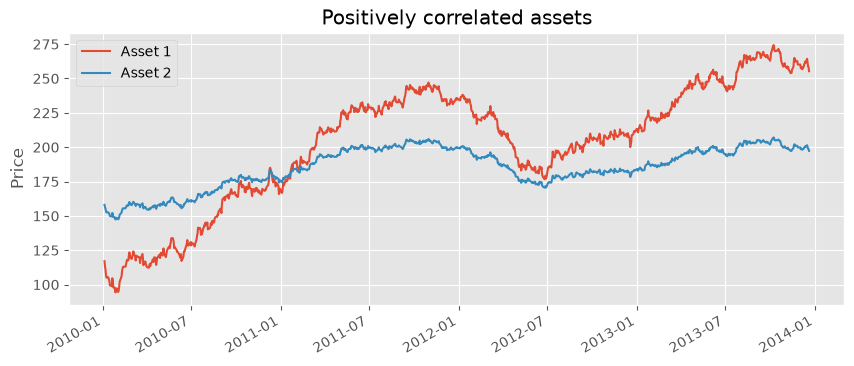

In [14]:
# Visualize the two price series
prices_pos.plot(figsize=(10, 4), title="Positively correlated assets")
plt.ylabel("Price")
plt.show()

### Exercise 7 — Estimate correlation from data

Using `returns_pos`:

1. Calculate the correlation between Asset 1 and Asset 2.
2. Calculate the mean return and volatility of each asset.
3. Create a 50%-50% portfolio.
4. Calculate its mean return and volatility.
5. Compare portfolio volatility with the volatility of the two individual assets.

In [15]:
# Your code here

### 10. Hands-on exercise — Build your own two-asset portfolio

Choose two stocks and download their daily Adjusted Close prices.

Suggested period:

**January 1, 2022 to January 1, 2026**

Then:

1. Calculate daily log returns.
2. Calculate the correlation between the two stocks.
3. Calculate the annualized return and volatility of each stock.
4. Generate 101 portfolios by varying the weight of stock 1 from 0% to 100%.
5. Plot all portfolios in the return-volatility plane.
6. Identify the minimum-volatility portfolio.
7. Explain whether diversification is important for this pair of stocks.

### Final question

> If you wanted stronger diversification, would you look for two assets with higher or lower correlation? Why?

In [16]:
# Your code here

In [17]:
# Your code here

In [18]:
# Your code here

In [19]:
# Your code here

In [20]:
# Your code here

## Summary

The main lesson of this notebook is:

> **Diversification does not come simply from owning more assets. It comes from combining assets that do not move perfectly together.**

Remember:

1. Portfolio expected return is a weighted average of asset expected returns.
2. Portfolio risk depends on asset volatilities **and correlation**.
3. Lower correlation generally creates greater diversification benefits.
4. With $\rho=1$, there is no diversification benefit.
5. With $\rho=-1$, diversification can theoretically eliminate volatility for a particular combination of weights.

## 11. Calculate portfolio statistics from daily log returns

We previously calculated portfolio volatility from asset volatilities and correlation. An alternative is to construct the portfolio's **daily return series** and then calculate its mean and standard deviation.

For fixed weights, the weighted combination

$$r_{P,t}=w_1r_{1,t}+w_2r_{2,t}$$



In [21]:
# Use the daily log returns already calculated earlier
returns_log = returns_pos.copy()

display(returns_log.head())
print("Dimensions:", returns_log.shape)


,Asset 1,Asset 2
2010-01-05,-0.033085,-0.011054
2010-01-06,-0.018468,-0.006132
2010-01-07,-0.037001,-0.011918
2010-01-08,-0.018928,-0.006057
2010-01-11,0.003051,0.000796


Dimensions: (999, 2)


### Exercise 8 — Calculate the same portfolio in two ways

Use a **40%-60% portfolio**. First calculate its mean log return and volatility from the two assets' statistics and correlation. Then calculate its daily **weighted log returns** and apply `.mean()` and `.std()`.

**Question:** Do the two methods give the same results (up to rounding)? Why?


In [22]:
# Your code here

In [23]:
# Your code here

In [24]:
# Your code here

## 12. Generate 1,000 random two-asset portfolios

Generate a **1,000 × 2** matrix of random weights and normalize each row to sum to 1.

Use matrix multiplication to calculate the **weighted daily log-return series** for all 1,000 portfolios:

$$\underbrace{R}_{T\times2}\;\underbrace{W^\top}_{2\times1000}=\underbrace{\widetilde R_P}_{T\times1000}$$

Here $R$ contains the two stocks' daily log returns. Each output column corresponds to one portfolio.


In [25]:
# Generate 1,000 random long-only portfolios
rng = np.random.default_rng(42)
weights_random = rng.random((1000, 2))
weights_random = weights_random / weights_random.sum(axis=1, keepdims=True)

print("Weights shape:", weights_random.shape)
print("First five portfolios:\n", weights_random[:5])
print("Do all rows sum to 1?", np.allclose(weights_random.sum(axis=1), 1))


Weights shape: (1000, 2)
First five portfolios:
 [[0.63813823 0.36186177]
 [0.55181022 0.44818978]
 [0.08803269 0.91196731]
 [0.49194528 0.50805472]
 [0.22145847 0.77854153]]
Do all rows sum to 1? True


### Exercise 9 — Use matrix multiplication

Using the **daily log returns** and random weights:

1. Calculate all 1,000 weighted daily portfolio log-return series in one operation.
2. Calculate each portfolio's mean log return and volatility.
3. Plot the return–volatility diagram, including the two individual stocks.

**Check:** If there are $T$ dates, what are the dimensions of the result?


In [26]:
# Your code here

### Exercise 10 — Find the least volatile random portfolio

Find the row of `weights_random` corresponding to the smallest value in `random_vols`.

**Question:** Why can the best random portfolio differ slightly from the exact minimum-volatility portfolio?

In [27]:
# Your code here

## 13. Do risk and correlation change over time?

So far we have estimated one volatility and one correlation for the full sample. Both can change over time.

A **63-trading-day rolling window** uses the 63 most recent daily log returns. The first 62 dates do not have a full window.


### Exercise 11 — Rolling Return and Volatility: Individual Assets vs Portfolio

Using the daily log returns of the two stocks and the **50%-50% portfolio**, perform the following analysis:

1. Calculate the **rolling mean return** of each stock and the portfolio using a 63-day window.
2. Plot the three rolling mean returns in the same figure.
3. Calculate the **rolling volatility** of each stock and the portfolio using the same window.
4. Plot the three rolling volatilities in a second figure.

**Questions:**

- How does the portfolio's rolling mean return compare with those of the individual stocks?
- Is the portfolio's rolling volatility always lower than the volatility of both stocks?
- Does the diversification benefit remain constant over time?

**Conclusion:** Explain how combining two assets affects portfolio return and risk, and why the benefits of diversification may change over time.

In [28]:
# Your code here

In [29]:
# Your code here

## 14. Rolling diversification gain

Calculate the portfolio's volatility from its **weighted daily log-return series**. Compare it with the volatility it would have if the stocks' log returns were perfectly positively correlated:

$$DG_t=1-\frac{\sigma_{P,t}}{0.5\sigma_{1,t}+0.5\sigma_{2,t}}$$

All three standard deviations use the **same 63-day window of daily log returns**. For example, $DG_t=0.20$ indicates a 20% reduction relative to the no-diversification benchmark for this weighted-log-return measure.


In [ ]:
# Rolling volatility of the two stocks' daily log returns
stock_vol = returns_log.rolling(window).std()
no_diversification_vol = 0.5 * stock_vol.iloc[:, 0] + 0.5 * stock_vol.iloc[:, 1]

portfolio_rolling_vol = portfolio_50.rolling(window).std()
rolling_dg = 1 - portfolio_rolling_vol / no_diversification_vol

rolling_dg.plot(figsize=(11, 4), title="63-day rolling diversification gain")
plt.ylabel("Diversification gain")
plt.show()

mean_dg = rolling_dg.mean()
sd_dg = rolling_dg.std()
min_dg = rolling_dg.min()
score = mean_dg - 0.5 * sd_dg

print(f"Mean DG: {mean_dg:.2%}")
print(f"SD DG: {sd_dg:.2%}")
print(f"Minimum DG: {min_dg:.2%}")
print(f"Score: {score:.2%}")


### Exercise 12 — Stability versus average benefit

Suppose Pair A has average diversification gain of **30%** and standard deviation of **4%**. Pair B has average gain of **35%** and standard deviation of **20%**.

Calculate $Score=Mean(DG)-0.5\,SD(DG)$ for both pairs. Which wins? Explain why the average gain alone is not enough.